1. Imports

In [1]:
# -------------------------------------------------------------------
# SECTION 1: IMPORTS
# Import all necessary packages
# -------------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo 

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


# Goal 1.1: Classification
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score, confusion_matrix, make_scorer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    accuracy_score
)

# Goal 1.2: Clustering
from sklearn.cluster import KMeans

# Goal 2.1: XAI (Explainable AI)
import shap

# Goal 1.2 Visualization
from sklearn.decomposition import PCA

2. Section: Load, Rename and clean data + dic

In [2]:
# -------------------------------------------------------------------
# SECTION 2: LOAD, RENAME, AND CLEAN DATA (OFFICIAL DICTIONARY)
# -------------------------------------------------------------------

# 2.1 Fetch data
statlog_german_credit_data = fetch_ucirepo(id=144) 
X = statlog_german_credit_data.data.features 
y = statlog_german_credit_data.data.targets

# 2.2 Clean target variable (y)
# 1 = Good, 2 = Bad -> We map to: 1 = Good, 0 = Bad
y_processed = y.squeeze().map({1: 1, 2: 0})
y_processed.name = 'Credit_Risk (0=Bad, 1=Good)'

# 2.3 Rename columns (Mapping based on description)
column_rename_dict = {
    'Attribute1': 'Checking_Account_Status',
    'Attribute2': 'Duration_in_Month',
    'Attribute3': 'Credit_History',
    'Attribute4': 'Purpose',
    'Attribute5': 'Credit_Amount',
    'Attribute6': 'Savings_Account',
    'Attribute7': 'Present_Employment_Since',
    'Attribute8': 'Installment_Rate_Percentage',
    'Attribute9': 'Personal_Status_Sex',
    'Attribute10': 'Other_Debtors_Guarantors',
    'Attribute11': 'Present_Residence_Since',
    'Attribute12': 'Property',
    'Attribute13': 'Age_in_Years',
    'Attribute14': 'Other_Installment_Plans',
    'Attribute15': 'Housing',
    'Attribute16': 'Number_of_Credits',
    'Attribute17': 'Job',
    'Attribute18': 'Number_of_Dependents',
    'Attribute19': 'Telephone',
    'Attribute20': 'Foreign_Worker'
}
X_renamed = X.rename(columns=column_rename_dict)

# 2.4 Map categorical values (Exact definitions from description)
value_replace_dict = {
    'Checking_Account_Status': {
        'A11': '< 0 DM', 
        'A12': '0 <= ... < 200 DM', 
        'A13': '>= 200 DM', 
        'A14': 'No Checking Account'
    },
    'Credit_History': {
        'A30': 'No credits taken/All paid back', 
        'A31': 'All at this bank paid back', 
        'A32': 'Existing paid back duly', 
        'A33': 'Delay in past', 
        'A34': 'Critical account/Other credits'
    },
    'Purpose': {
        'A40': 'Car (new)', 
        'A41': 'Car (used)', 
        'A42': 'Furniture/Equipment', 
        'A43': 'Radio/Television', 
        'A44': 'Domestic Appliances', 
        'A45': 'Repairs', 
        'A46': 'Education', 
        'A47': 'Vacation', 
        'A48': 'Retraining', 
        'A49': 'Business', 
        'A410': 'Others'
    },
    #oridnalität?
    'Savings_Account': {
        'A61': '< 100 DM', 
        'A62': '100 <= ... < 500 DM', 
        'A63': '500 <= ... < 1000 DM', 
        'A64': '>= 1000 DM', 
        'A65': 'Unknown/No Savings Account'
    },
    'Present_Employment_Since': {
        'A71': 'Unemployed', 
        'A72': '< 1 year', 
        'A73': '1 <= ... < 4 years', 
        'A74': '4 <= ... < 7 years', 
        'A75': '>= 7 years'
    },
    'Personal_Status_Sex': {
        'A91': 'Male: Divorced/Separated', 
        'A92': 'Female: Divorced/Separated/Married', 
        'A93': 'Male: Single', 
        'A94': 'Male: Married/Widowed', 
        'A95': 'Female: Single'
    },
    'Other_Debtors_Guarantors': {'A101': 'None', 'A102': 'Co-applicant', 'A103': 'Guarantor'},
    'Property': {
        'A121': 'Real Estate', 
        'A122': 'Building Society/Life Insurance', 
        'A123': 'Car/Other', 
        'A124': 'Unknown/No Property'
    },
    'Other_Installment_Plans': {'A141': 'Bank', 'A142': 'Stores', 'A143': 'None'},
    'Housing': {'A151': 'Rent', 'A152': 'Own', 'A153': 'For Free'},
    'Job': {
        'A171': 'Unemployed/Unskilled (non-res)', 
        'A172': 'Unskilled (resident)', 
        'A173': 'Skilled Employee/Official', 
        'A174': 'Management/Self-employed/Officer'
    },
    'Telephone': {'A191': 'None', 'A192': 'Yes'},
    'Foreign_Worker': {'A201': 'Yes', 'A202': 'No'}
}
X_cleaned = X_renamed.replace(value_replace_dict)

print(X_cleaned.head())
print("\n")

  Checking_Account_Status  Duration_in_Month                  Credit_History  \
0                  < 0 DM                  6  Critical account/Other credits   
1       0 <= ... < 200 DM                 48         Existing paid back duly   
2     No Checking Account                 12  Critical account/Other credits   
3                  < 0 DM                 42         Existing paid back duly   
4                  < 0 DM                 24                   Delay in past   

               Purpose  Credit_Amount             Savings_Account  \
0     Radio/Television           1169  Unknown/No Savings Account   
1     Radio/Television           5951                    < 100 DM   
2            Education           2096                    < 100 DM   
3  Furniture/Equipment           7882                    < 100 DM   
4            Car (new)           4870                    < 100 DM   

  Present_Employment_Since  Installment_Rate_Percentage  \
0               >= 7 years                   

3. Data Preprocessing

In [3]:
# -------------------------------------------------------------------
# SECTION 3: DATA PREPROCESSING
# -------------------------------------------------------------------

# 3.1 Define column types based on the NEW names
numeric_features = [
    'Duration_in_Month', 
    'Credit_Amount', 
    'Installment_Rate_Percentage', 
    'Present_Residence_Since', 
    'Age_in_Years', 
    'Number_of_Credits', 
    'Number_of_Dependents'
]

categorical_features = [
    'Checking_Account_Status', 
    'Credit_History', 
    'Purpose', 
    'Savings_Account', 
    'Present_Employment_Since', 
    'Personal_Status_Sex', 
    'Other_Debtors_Guarantors', 
    'Property', 
    'Other_Installment_Plans', 
    'Housing', 
    'Job', 
    'Telephone', 
    'Foreign_Worker'
]

# 3.2 Create the preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
#Vielleicht Label Encoder für Ordinale?
# 3.3 Combine pipelines with ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

4. Micro Goal 1.1 (Cost-sensitive Classification)

In [ ]:
# -------------------------------------------------------------------
# ABSCHNITT 4 (FINAL): ROC-AUC OPTIMIERUNG & BUSINESS KOMPROMISS
# -------------------------------------------------------------------

# 4.1 Split data 20 % Test
X_train, X_test, y_train, y_test = train_test_split(
    X_cleaned, y_processed, 
    test_size=0.20, 
    random_state=42, 
    stratify=y_processed
)

# 4.2 Pipeline Random Forest
rf = RandomForestClassifier(random_state=42)

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', rf)
])

# 4.3 Balanced Parameter
param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [8, 12, None], # Less against Overfitting
    'model__min_samples_leaf': [2, 4, 6],
    'model__class_weight': ['balanced', 'balanced_subsample'] 
}

# 4.4 Grid Search (ROC-AUC)
grid_search = GridSearchCV(
    pipeline, 
    param_grid, 
    cv=5, 
    scoring='roc_auc', 
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print(f"Best Setting: {grid_search.best_params_}")


# Threshold Tuning
y_proba = best_model.predict_proba(X_test)[:, 1]
thresholds = np.arange(0.0, 1.01, 0.01)

best_threshold = 0.5
best_score = float('inf')

results = []

for t in thresholds:
    y_pred_t = (y_proba >= t).astype(int)
    cm = confusion_matrix(y_test, y_pred_t, labels=[0, 1])
    
    # Extract
    tn, fp, fn, tp = cm.ravel()
    
    # Costs
    cost = (fp * 5) + (fn * 1)
    
    # 2. "Frust-Faktor": Wie viel Prozent der GUTEN Kunden lehnen wir ab?
    # (False Negatives / Alle Guten)
    # y_test==1 gibt uns alle Guten
    total_good_customers = (y_test == 1).sum()
    rejection_rate_good_customers = fn / total_good_customers if total_good_customers > 0 else 0
    
    # UNSERE STRATEGIE:
    # Wir wollen minimale Kosten, ABER wir akzeptieren keine Lösung, 
    # die mehr als 25% der guten Kunden vergrault.
    if rejection_rate_good_customers <= 0.25: # MAXIMAL 25% Frust akzeptieren
        if cost < best_score:
            best_score = cost
            best_threshold = t
    
    results.append((t, cost, rejection_rate_good_customers))

# -------------------------------------------------------------------
# FINALE EVALUATION
# -------------------------------------------------------------------
print(f"\nCompromise {best_threshold:.2f}")

final_y_pred = (y_proba >= best_threshold).astype(int)
cm = confusion_matrix(y_test, final_y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("\nConfusion Matrix:")
print(cm)
print(f"\nDetails:")
print(f"True Negative: {tn}")
print(f"True Positive: {tp}")
print(f"False : {fn}")
print(f"FALSCH ANGENOMMEN (Kreditausfälle):       {fp}")
print("-" * 30)
print(f"GESAMTKOSTEN (Weighted): {best_score}")

# Managerial Insight für die Präsentation:
total_good = fn + tp
frust_quote = (fn/total_good)*100
print(f"\nManagerial Insight:")
print(f"Mit diesem Modell fangen wir die Risiken ab, verärgern aber nur {frust_quote:.1f}% der guten Kunden.")
print("Das ist eine Balance aus Sicherheit (Kosten) und Wachstum (Marktanteil).")

# Update für Pipeline
classification_pipeline = best_model

Best Setting: {'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 4, 'model__n_estimators': 100}

Compromise 0.50

Confusion Matrix:
[[ 40  20]
 [ 32 108]]

Details:
True Negative: 40
True Positive: 108
False : 32
FALSCH ANGENOMMEN (Kreditausfälle):       20
------------------------------
GESAMTKOSTEN (Weighted): 132

Managerial Insight:
Mit diesem Modell fangen wir die Risiken ab, verärgern aber nur 22.9% der guten Kunden.
Das ist eine Balance aus Sicherheit (Kosten) und Wachstum (Marktanteil).


5. Micro Goal 1.2 Clustering

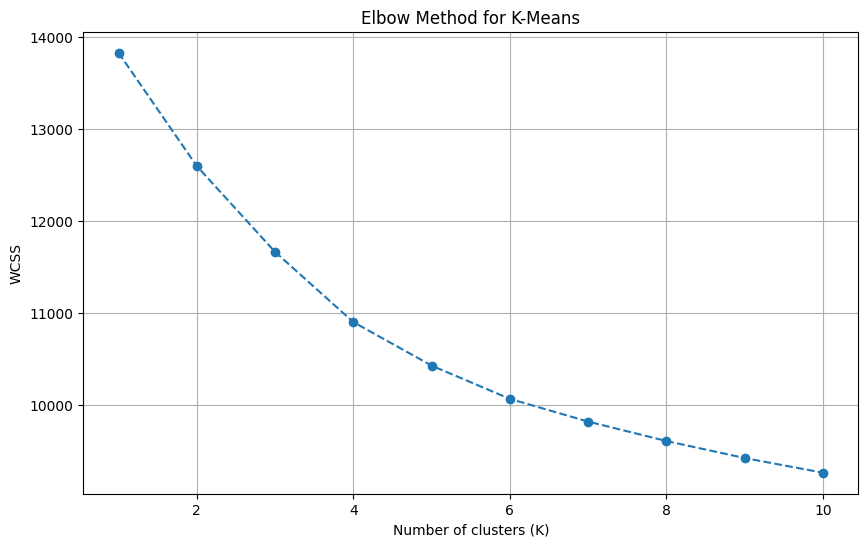

Final K-Means model trained with K=3.




In [5]:
# -------------------------------------------------------------------
# SECTION 5: MICRO-GOAL 1.2 (CLUSTERING)
# -------------------------------------------------------------------

# 5.1 Prepare data for clustering (using X_cleaned)
X_processed = preprocessor.fit_transform(X_cleaned)

# 5.2 Elbow Method
wcss = []
k_range = range(1, 11)
for i in k_range:
    kmeans = KMeans(n_clusters=i, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(X_processed)
    wcss.append(kmeans.inertia_)

# Plot Elbow Method
plt.figure(figsize=(10, 6))
plt.plot(k_range, wcss, marker='o', linestyle='--')
plt.title('Elbow Method for K-Means')
plt.xlabel('Number of clusters (K)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

# 5.3 Train final K-Means model
chosen_k = 3 
final_kmeans = KMeans(n_clusters=chosen_k, init='k-means++', n_init=10, random_state=42)
cluster_labels = final_kmeans.fit_predict(X_processed)

print(f"Final K-Means model trained with K={chosen_k}.")
print("\n")

6. Micro Goal 2.1 XAI with Shap


--- Globale Modellerklärung (Feature Importance) ---


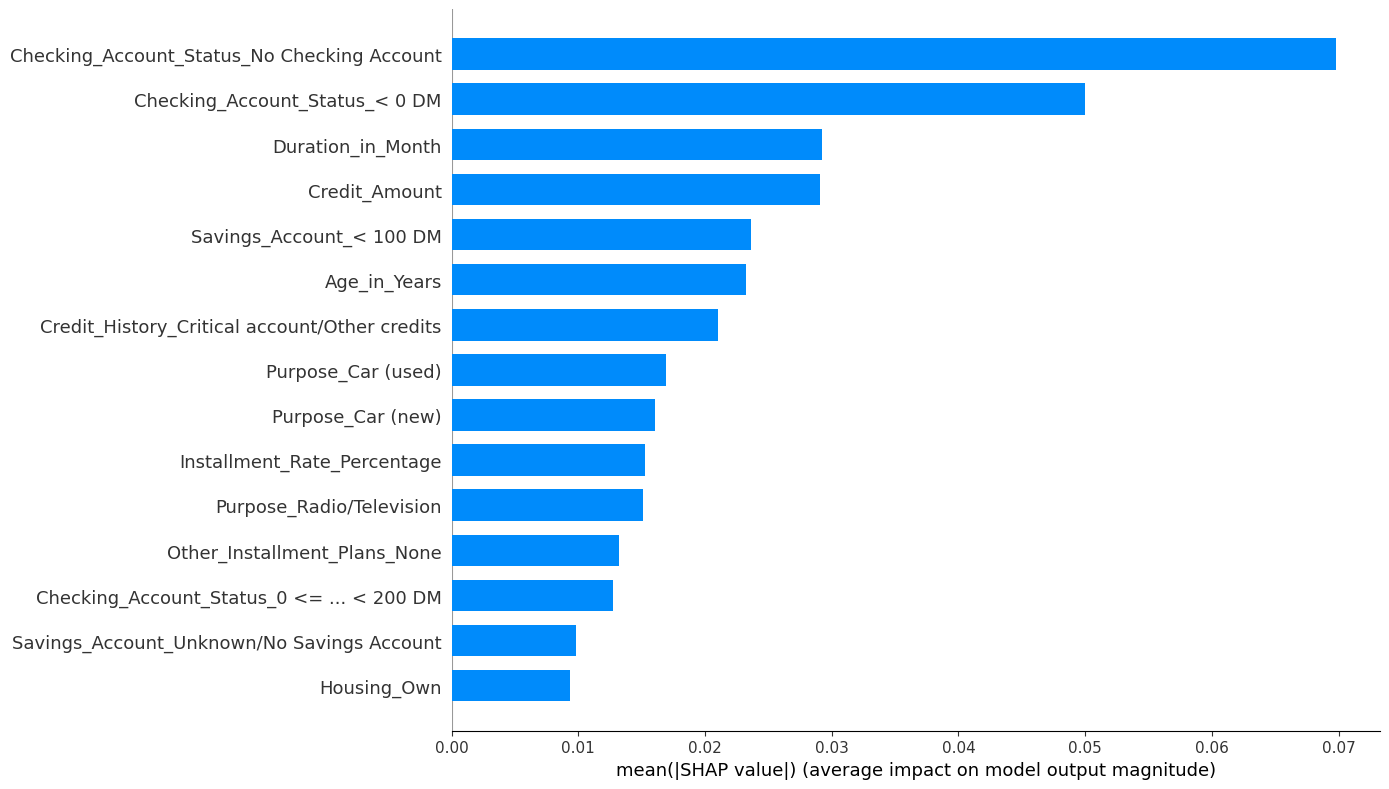


--- Lokale Modellerklärung (Waterfall Plots) ---

--- Erklärung für Kunde 0 ---
Tatsächliches Risiko: GUT (1)


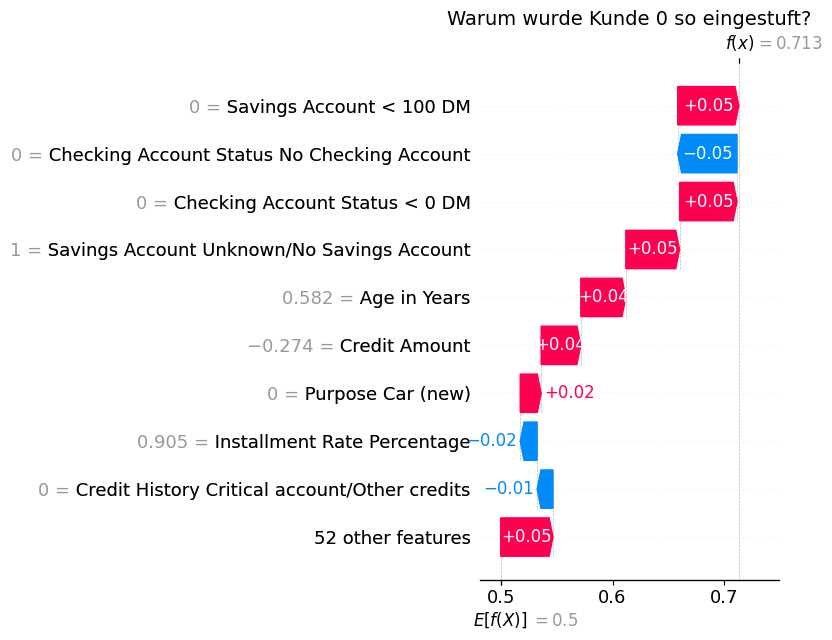


--- Erklärung für Kunde 1 ---
Tatsächliches Risiko: GUT (1)


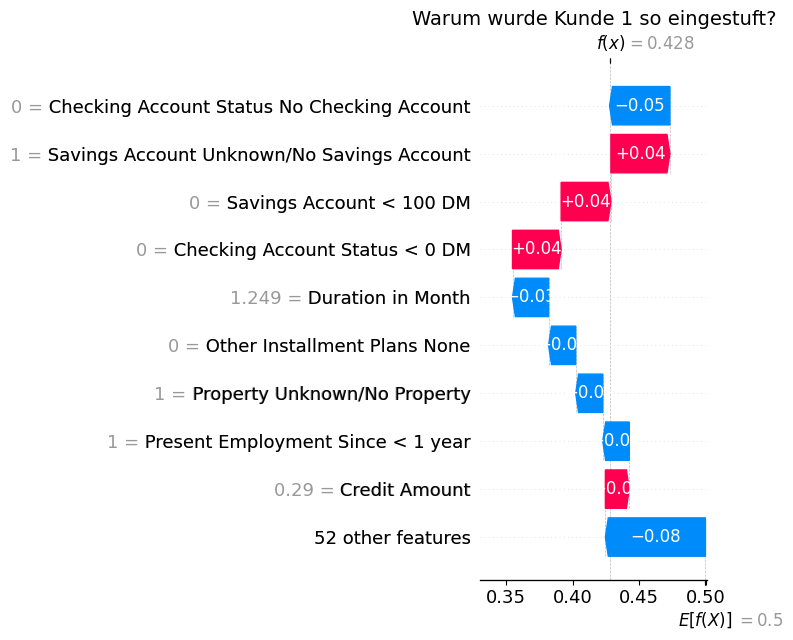


--- Erklärung für Kunde 2 ---
Tatsächliches Risiko: GUT (1)


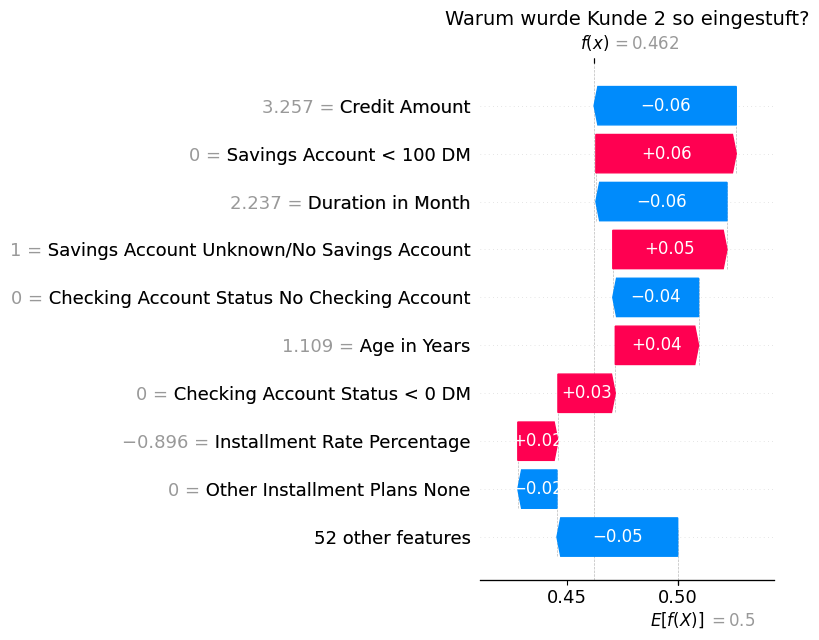

In [6]:
# -------------------------------------------------------------------
# SECTION 6: MICRO-GOAL 2.1 (XAI WITH SHAP)
# -------------------------------------------------------------------

# 6.1 Extract model and preprocessor
model_for_shap = classification_pipeline.named_steps['model']
preprocessor_for_shap = classification_pipeline.named_steps['preprocessor']

# 6.2 Transform test data and get feature names
X_test_processed = preprocessor_for_shap.transform(X_test)
feature_names = preprocessor_for_shap.get_feature_names_out()

# 6.3 Initialize SHAP Explainer and calculate values
explainer = shap.TreeExplainer(model_for_shap)
shap_values = explainer.shap_values(X_test_processed)

# 6.4 (SHAP PLOT)
clean_feature_names = [name.replace('cat__', '').replace('num__', '') for name in feature_names]

print("\n--- Globale Modellerklärung (Feature Importance) ---")
shap_values_for_plot = shap_values[:, :, 1]
shap.initjs() 

# plot_size
shap.summary_plot(shap_values_for_plot, 
                  X_test_processed,
                  feature_names=clean_feature_names, # Die sauberen Namen nutzen
                  plot_type="bar", 
                  max_display=15,                    # Nur die Top 15 anzeigen
                  plot_size=(14, 8),                 # Bild größer machen
                  show=False,                        # Nicht sofort anzeigen, damit wir noch formatieren können
                  title="Globale Feature Importance (Top 15)")

plt.tight_layout() 
plt.show()         

# -------------------------------------------------------------------
# KORRIGIERTER ABSCHNITT 6.5 (Waterfall Plot für perfekte Lesbarkeit)
# -------------------------------------------------------------------
print("\n--- Lokale Modellerklärung (Waterfall Plots) ---")

# 1. Feature-Namen bereinigen
clean_feature_names = [name.replace('cat__', '').replace('num__', '').replace('_', ' ') for name in feature_names]

# Wir schauen uns 3 Instanzen an
instances_to_explain = [0, 1, 2]

for instance_index in instances_to_explain:
    # Echte Entscheidung holen
    actual_label = "GUT (1)" if y_test.iloc[instance_index] == 1 else "SCHLECHT (0)"
    
    print(f"\n--- Erklärung für Kunde {instance_index} ---")
    print(f"Tatsächliches Risiko: {actual_label}")

    # WICHTIG: Wir erstellen ein 'Explanation'-Objekt. 
    # Das ist notwendig für den modernen Waterfall-Plot.
    explanation = shap.Explanation(
        values = shap_values[instance_index, :, 1], # Die SHAP-Werte für Klasse 1
        base_values = explainer.expected_value[1],  # Der Basiswert
        data = X_test_processed[instance_index],    # Die echten Daten dieses Kunden
        feature_names = clean_feature_names         # Die sauberen Namen
    )

    # Plot erstellen
    plt.figure(figsize=(10, 6)) # Größe anpassen
    
    # max_display=10 zeigt nur die Top 10 Features an (der Rest wird zusammengefasst)
    # Das verhindert Überlappung garantiert!
    shap.plots.waterfall(explanation, max_display=10, show=False)
    
    plt.title(f"Warum wurde Kunde {instance_index} so eingestuft?", fontsize=14)
    plt.tight_layout()
    plt.show()

7. Cluster Analysis and Export (Goal 2.1/2.2)

In [7]:
# -------------------------------------------------------------------
# SECTION 7: CLUSTER ANALYSIS & EXPORT (GOAL 2.1/2.2)
# -------------------------------------------------------------------
# Nur die wichtigsten Attribute für die Analyse nutzen
# 7.1 Prepare data for cluster analysis and export
# We add cluster labels and risk to our clean DataFrame 'X_cleaned'
X_with_clusters = X_cleaned.copy()
X_with_clusters['Customer_Segment'] = cluster_labels
X_with_clusters['Credit_Risk (0=Bad, 1=Good)'] = y_processed 

# 7.2 Cluster Analysis (Guiding Question 2.1 / Task 3)
print("\n--- Cluster Analysis (Basis for Task 2.1 / 3) ---")
print(f"Average values of numeric features per cluster (K={chosen_k}):")
# 'numeric_features' list from Section 3.1
print(X_with_clusters.groupby('Customer_Segment')[numeric_features].mean())
print("\n")

# 7.3 Export for PowerBI (Guiding Question 2.2)
output_filename_final = "german_credit_data_renamed_final.csv"
X_with_clusters.to_csv(output_filename_final, index=False)

print(f"Final data successfully saved to '{output_filename_final}'.")
print("\n")


--- Cluster Analysis (Basis for Task 2.1 / 3) ---
Average values of numeric features per cluster (K=3):
                  Duration_in_Month  Credit_Amount  \
Customer_Segment                                     
0                         16.655689    2327.209581   
1                         38.628415    7831.213115   
2                         17.124224    2196.393375   

                  Installment_Rate_Percentage  Present_Residence_Since  \
Customer_Segment                                                         
0                                    3.200599                 3.500000   
1                                    2.644809                 2.846995   
2                                    2.939959                 2.391304   

                  Age_in_Years  Number_of_Credits  Number_of_Dependents  
Customer_Segment                                                         
0                    45.251497           1.649701              1.302395  
1                    35.174863 

8. Cluster Visualization with PCA

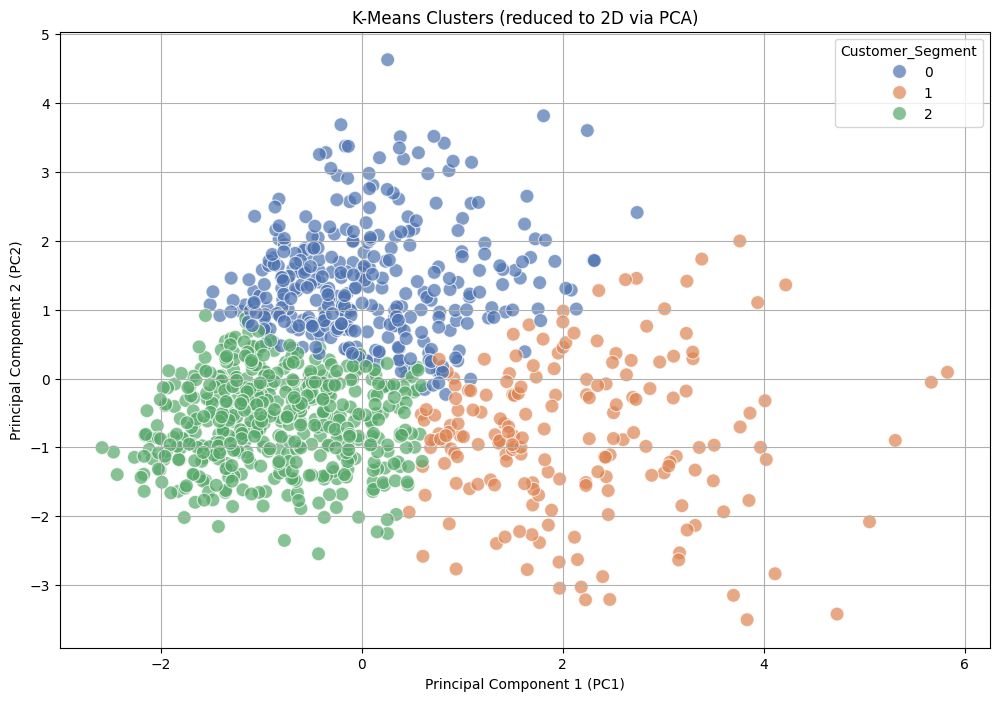



Erstelle statische 3D-Ansichten aus 3 Perspektiven...


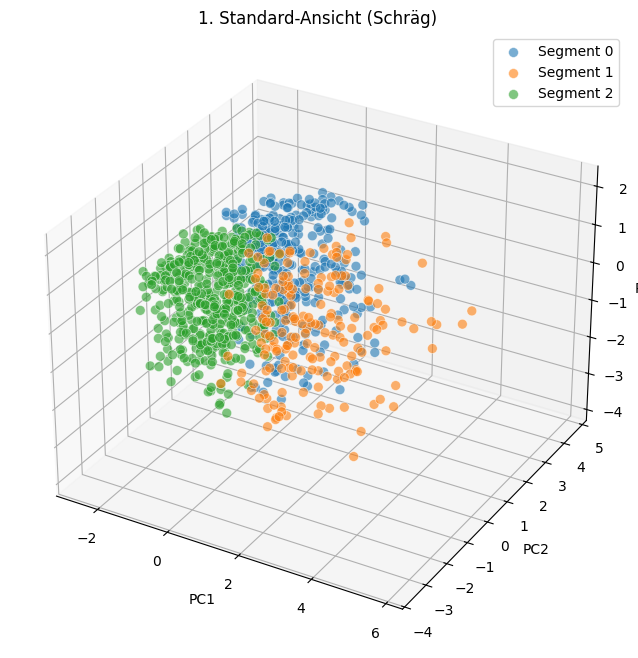

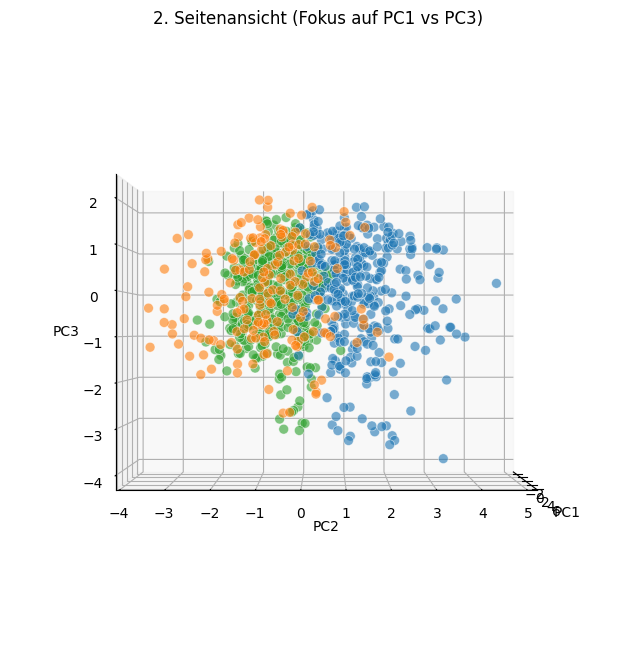

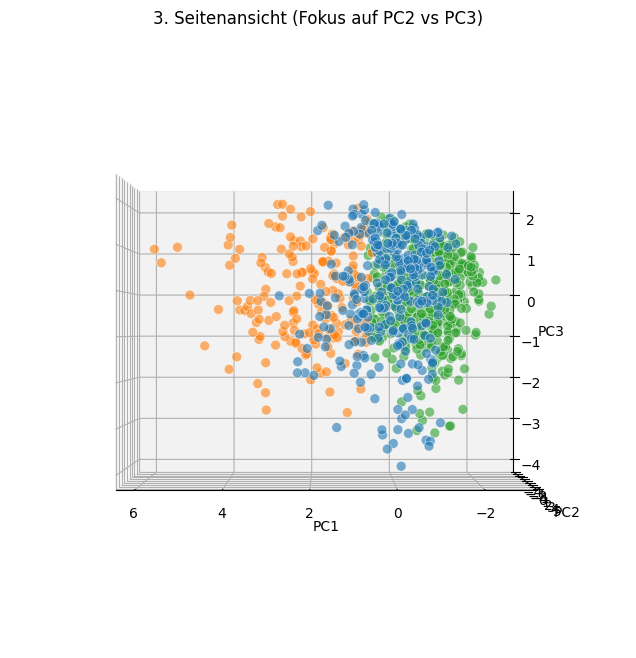

In [8]:
# -------------------------------------------------------------------
# SECTION 8: CLUSTER VISUALIZATION (PCA)
# -------------------------------------------------------------------

# 8.1 PCA Model (reducing from 61 to 2 dimensions)
# We use X_processed (from Section 5) as K-Means was trained on it
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_processed)

# 8.2 Create DataFrame for plotting
pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
pca_df['Customer_Segment'] = cluster_labels # cluster_labels (from Section 5)
pca_df['Customer_Segment'] = pca_df['Customer_Segment'].astype('category')

# 8.3 Create the scatterplot
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x="PC1", y="PC2",
    hue="Customer_Segment",
    palette=sns.color_palette("deep", n_colors=chosen_k),
    data=pca_df,
    legend="full",
    alpha=0.7,
    s=100
)
plt.title('K-Means Clusters (reduced to 2D via PCA)')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.grid(True)
plt.show()
print("\n")

# -------------------------------------------------------------------
# ZUSATZ: STATISCHE 3D-CLUSTER (3 PERSPEKTIVEN)
# -------------------------------------------------------------------
print("Erstelle statische 3D-Ansichten aus 3 Perspektiven...")

from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

# 1. Daten vorbereiten (PCA auf 3D)
# Wir nutzen X_processed (skalierte Daten) für die PCA
pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X_processed)

df_pca_3d = pd.DataFrame(X_pca_3d, columns=['PC1', 'PC2', 'PC3'])
df_pca_3d['Kundensegment'] = cluster_labels

# Hilfsfunktion zum Plotten, damit wir Code sparen
def plot_3d_view(ax, elevation, azimuth, title):
    colors = plt.cm.tab10(np.linspace(0, 1, chosen_k))
    
    for i in range(chosen_k):
        subset = df_pca_3d[df_pca_3d['Kundensegment'] == i]
        ax.scatter(subset['PC1'], subset['PC2'], subset['PC3'], 
                   label=f'Segment {i}', 
                   s=50, alpha=0.6, edgecolors='w', linewidth=0.5)
    
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.set_zlabel('PC3')
    ax.set_title(title)
    
    # Hier wird die Kamera gedreht!
    ax.view_init(elev=elevation, azim=azimuth) 

# --- Bild 1: Standard-Ansicht (Schräg) ---
fig1 = plt.figure(figsize=(10, 8))
ax1 = fig1.add_subplot(111, projection='3d')
plot_3d_view(ax1, elevation=30, azimuth=-60, title="1. Standard-Ansicht (Schräg)")
ax1.legend()
plt.show()

# --- Bild 2: Blick auf die PC2-PC3 Ebene (Blick entlang PC1) ---
# Azimut 0 bedeutet oft Blick auf die X-Z Ebene (PC1-PC3). 
# Azimut 90 dreht es um 90 Grad.
fig2 = plt.figure(figsize=(10, 8))
ax2 = fig2.add_subplot(111, projection='3d')
plot_3d_view(ax2, elevation=0, azimuth=0, title="2. Seitenansicht (Fokus auf PC1 vs PC3)")
# Hier sehen wir gut, wie PC1 und PC3 trennen (PC2 verschwindet in der Tiefe)
plt.show()

# --- Bild 3: Blick auf die PC1-PC3 Ebene (Gedreht) ---
fig3 = plt.figure(figsize=(10, 8))
ax3 = fig3.add_subplot(111, projection='3d')
plot_3d_view(ax3, elevation=0, azimuth=90, title="3. Seitenansicht (Fokus auf PC2 vs PC3)")
# Hier sehen wir gut, wie PC2 und PC3 trennen (PC1 verschwindet in der Tiefe/kommt auf uns zu)
plt.show()

9. Cluster Visualization with a Pairplot

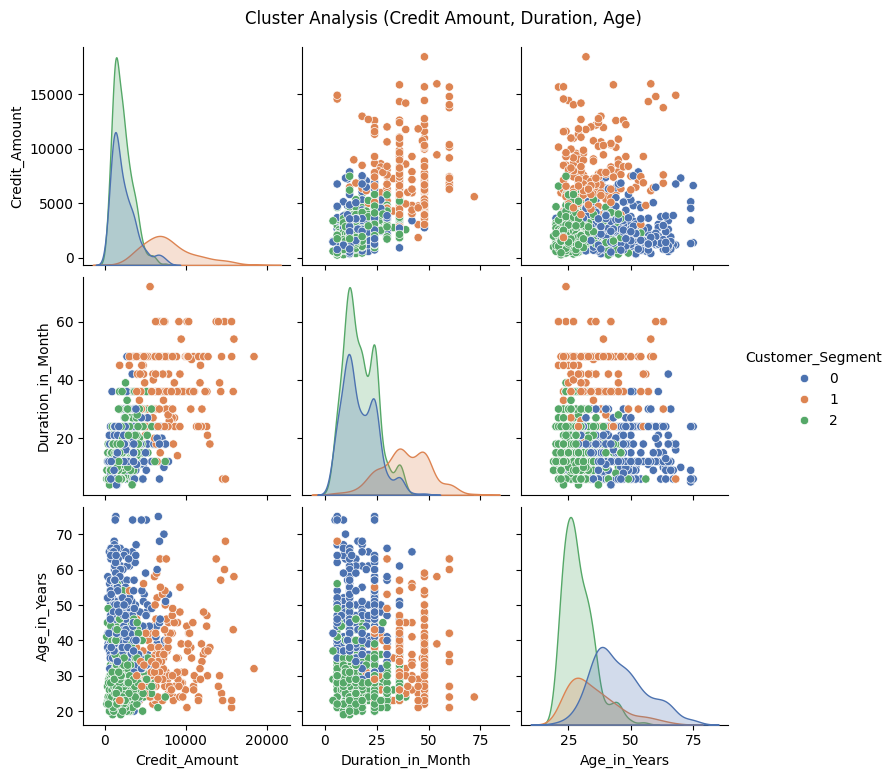

In [9]:
# -------------------------------------------------------------------
# SECTION 9: CLUSTER VISUALIZATION (PAIRPLOT)
# -------------------------------------------------------------------

# 9.1 Select the readable column names
features_to_plot_renamed = ['Credit_Amount', 'Duration_in_Month', 'Age_in_Years']

# 9.2 Create the pairplot using the clean DataFrame 'X_with_clusters'
sns.pairplot(X_with_clusters, 
             vars=features_to_plot_renamed, 
             hue='Customer_Segment', 
             palette=sns.color_palette("deep", n_colors=chosen_k)
            )
plt.suptitle('Cluster Analysis (Credit Amount, Duration, Age)', y=1.03)
plt.show()